# Automating Crupto Website API

In [33]:

from requests import Request, Session
from requests.exceptions import ConnectionError, Timeout, TooManyRedirects
import json

url = 'https://api.coingecko.com/api/v3/coins/markets'

Parameters = {
    'vs_currency': 'usd',
    'order': 'market_cap_desc',
    'per_page': '20',
    'page': '1',
    'sparkline': 'false'
}

headers = {
    'accept': 'application/json',
    'x-cg-demo-api-key': 'CG-A1vUD3P41ZQt6WP5nJKa5Y6s'
}

session = Session()
session.headers.update(headers)

try:
    response = session.get(
        url,
        params=Parameters,
        timeout=(10, 60)
    )
    response.raise_for_status()
    data = json.loads(response.text)

except (ConnectionError, Timeout, TooManyRedirects) as e:
    print(e)

In [34]:
type(data)

list

In [35]:
import pandas as pd

In [36]:
pd.set_option('display.max.columns', None)
pd.set_option('display.max.rows', None)

In [37]:
df = pd.json_normalize(data)
df['timestamp'] = pd.to_datetime('now')
df

,id,symbol,name,image,current_price,market_cap,market_cap_rank,fully_diluted_valuation,total_volume,high_24h,low_24h,price_change_24h,price_change_percentage_24h,market_cap_change_24h,market_cap_change_percentage_24h,circulating_supply,total_supply,max_supply,ath,ath_change_percentage,ath_date,atl,atl_change_percentage,atl_date,roi,last_updated,roi.times,roi.currency,roi.percentage,timestamp
0,bitcoin,btc,Bitcoin,https://coin-images.coingecko.com/coins/images...,82943.000000,1667601620463,1,1667601620463,24660692822,82457.000000,81155.000000,918.760000,1.116820,19002635491.000000,1.152650,20098843.000000,20098843.000000,21000000.000000,126080.000000,-34.213670,2025-10-06T10:57:42.000Z,67.810000,122219.059340,2013-07-05T16:00:00.000Z,NaN,2026-10-20T14:13:53.000Z,NaN,NaN,NaN,2026-10-20 19:46:15.632691
1,ethereum,eth,Ethereum,https://coin-images.coingecko.com/coins/images...,2446.770000,298994946198,2,298994946198,9337438026,2418.380000,2374.520000,52.340000,2.171280,6519710019.000000,2.229150,122151332.394953,122151332.394953,NaN,4946.050000,-50.530880,2025-08-24T11:21:03.000Z,0.432979,565000.695640,2015-10-19T16:00:00.000Z,NaN,2026-10-20T14:13:53.000Z,43.309090,btc,4330.908963,2026-10-20 19:46:15.632691
2,tether,usdt,Tether,https://coin-images.coingecko.com/coins/images...,0.999153,183026594480,3,188489077334,47120592006,0.999418,0.999032,-0.000147,-0.015710,-509995140.772919,-0.277870,183176219727.943329,188643168191.576202,NaN,1.320000,-24.483650,2018-07-23T16:00:00.000Z,0.572521,74.518180,2015-03-01T16:00:00.000Z,NaN,2026-10-20T14:13:53.000Z,NaN,NaN,NaN,2026-10-20 19:46:15.632691
3,binancecoin,bnb,BNB,https://coin-images.coingecko.com/coins/images...,738.260000,97092436662,4,97092436662,626006265,733.050000,723.750000,12.370000,1.722090,1629328947.000000,1.706760,131512026.940000,131512026.940000,200000000.000000,1369.990000,-46.112300,2025-10-13T00:41:24.000Z,0.039818,1853992.707350,2017-10-18T16:00:00.000Z,NaN,2026-10-20T14:13:53.000Z,NaN,NaN,NaN,2026-10-20 19:46:15.632691
4,ripple,xrp,XRP,https://coin-images.coingecko.com/coins/images...,1.330000,83853818472,5,132808786457,1341779114,1.310000,1.290000,0.030876,2.463650,2013911026.000000,2.460790,63129671205.000000,99985607990.000000,100000000000.000000,3.650000,-63.600760,2025-07-17T19:40:53.000Z,0.002686,49309.974170,2014-05-21T16:00:00.000Z,NaN,2026-10-20T14:13:53.000Z,NaN,NaN,NaN,2026-10-20 19:46:15.632691
5,usd-coin,usdc,USDC,https://coin-images.coingecko.com/coins/images...,0.999801,72079841387,6,72081253727,16505653603,1.001000,0.999321,-0.000121,-0.011370,-281230027.230301,-0.388650,72092031784.482117,72093444363.253967,NaN,1.043000,-4.184460,2018-11-14T16:00:00.000Z,0.877647,13.918430,2023-03-11T00:02:13.000Z,NaN,2026-10-20T14:13:53.000Z,NaN,NaN,NaN,2026-10-20 19:46:15.632691
6,solana,sol,Solana,https://coin-images.coingecko.com/coins/images...,106.940000,63067062742,7,68052345078,2308128519,105.510000,103.620000,3.100000,3.049910,1855668127.000000,3.031570,589549798.507090,636152130.511034,NaN,293.310000,-63.541290,2025-01-19T03:15:27.000Z,0.500801,21253.335970,2020-05-11T11:35:23.000Z,NaN,2026-10-20T14:13:53.000Z,NaN,NaN,NaN,2026-10-20 19:46:15.632691
7,tron,trx,TRON,https://coin-images.coingecko.com/coins/images...,0.331115,31462157124,8,31462166055,308134485,0.332370,0.330330,-0.001068,-0.281050,-96493168.703438,-0.305760,95005279984.181961,95005306953.936569,NaN,0.431288,-23.226570,2024-12-03T16:10:40.000Z,0.001804,18251.008130,2017-11-11T16:00:00.000Z,NaN,2026-10-20T14:13:53.000Z,175.853881,usd,17585.388090,2026-10-20 19:46:15.632691
8,figure-heloc,figr_heloc,Figure Heloc,https://coin-images.coingecko.com/coins/images...,1.021000,24515093803,9,24515093803,17615338,1.040000,1.020000,-0.002534,-0.250590,-65510679.879711,-0.266510,24018021967.487999,24018021967.487999,NaN,1.075000,-5.073540,2026-10-05T13:59:20.000Z,0.155357,557.022660,2025-10-31T06:27:24.000Z,NaN,2026-10-20T14:13:53.000Z,NaN,NaN,NaN,2026-10-20 19:46:15.632691
9,zcash,zec,Zcash,https://coin-imag

In [38]:
df = pd.DataFrame()
def api_runner():
    global df
    url = 'https://api.coingecko.com/api/v3/coins/markets'
    
    Parameters = {
        'vs_currency': 'usd',
        'order': 'market_cap_desc',
        'per_page': '20',
        'page': '1',
        'sparkline': 'false'
    }
    
    headers = {
        'accept': 'application/json',
        'x-cg-demo-api-key': 'CG-A1vUD3P41ZQt6WP5nJKa5Y6s'
    }
    
    session = Session()
    session.headers.update(headers)
    
    try:
        response = session.get(
            url,
            params=Parameters,
            timeout=(10, 60)
        )
        response.raise_for_status()
        data = json.loads(response.text)
    
    except (ConnectionError, Timeout, TooManyRedirects) as e:
        print(e)

    df = pd.json_normalize(data)
    df['timestamp'] = pd.to_datetime('now')

    if not os.path.isfile(r'D:/OMKAR/Python/Crypto automation Project/API.csv'):
        df.to_csv(r'D:/OMKAR/Python/Crypto automation Project/API.csv', header='column_names', index=False)
    else:
        df.to_csv(r'D:/OMKAR/Python/Crypto automation Project/API.csv', mode='a', header=False, index=False)


In [39]:
import os
from time import time
from time import sleep

for i in range(333):
    api_runner()
    print("api runner completed")
    sleep(6)
exit()    

api runner completed
api runner completed
api runner completed


KeyboardInterrupt: 

In [40]:
df27 = pd.read_csv(r'D:/OMKAR/Python/Crypto automation Project/API.csv')
df27

,id,symbol,name,image,current_price,market_cap,market_cap_rank,fully_diluted_valuation,total_volume,high_24h,low_24h,price_change_24h,price_change_percentage_24h,market_cap_change_24h,market_cap_change_percentage_24h,circulating_supply,total_supply,max_supply,ath,ath_change_percentage,ath_date,atl,atl_change_percentage,atl_date,roi,last_updated,roi.times,roi.currency,roi.percentage,timestamp
0,bitcoin,btc,Bitcoin,https://coin-images.coingecko.com/coins/images...,81352.000000,1635101815106,1,1635101815106,24869617096,82807.000000,81155.000000,-1349.362718,-1.631610,-27100621205.458248,-1.630400,20098843.000000,20098843.000000,21000000.000000,126080.000000,-35.475800,2025-10-06T10:57:42.000Z,67.810000,119872.328720,2013-07-05T16:00:00.000Z,NaN,2026-10-20T09:09:46.000Z,NaN,NaN,NaN,2026-10-20 14:40:43.445304
1,ethereum,eth,Ethereum,https://coin-images.coingecko.com/coins/images...,2378.680000,290558610380,2,290558610380,9367360824,2436.650000,2374.520000,-54.391632,-2.235510,-6637658979.614136,-2.233430,122151332.394953,122151332.394953,NaN,4946.050000,-51.907350,2025-08-24T11:21:03.000Z,0.432979,549276.858830,2015-10-19T16:00:00.000Z,NaN,2026-10-20T09:09:46.000Z,43.309090,btc,4330.908963,2026-10-20 14:40:43.445304
2,tether,usdt,Tether,https://coin-images.coingecko.com/coins/images...,0.999100,183015330664,3,188477477346,46233736919,0.999436,0.999095,-0.000216,-0.021620,-524118506.951233,-0.285560,183176219727.943329,188643168191.576202,NaN,1.320000,-24.487660,2018-07-23T16:00:00.000Z,0.572521,74.508920,2015-03-01T16:00:00.000Z,NaN,2026-10-20T09:09:46.000Z,NaN,NaN,NaN,2026-10-20 14:40:43.445304
3,binancecoin,bnb,BNB,https://coin-images.coingecko.com/coins/images...,726.690000,95569205576,4,95569205576,662319709,732.900000,722.800000,1.150000,0.158580,-1042033122.766281,-1.078580,131512037.910000,131512037.910000,200000000.000000,1369.990000,-46.956810,2025-10-13T00:41:24.000Z,0.039818,1824935.990530,2017-10-18T16:00:00.000Z,NaN,2026-10-20T09:09:46.000Z,NaN,NaN,NaN,2026-10-20 14:40:43.445304
4,ripple,xrp,XRP,https://coin-images.coingecko.com/coins/images...,1.290000,81531468214,5,129130617412,1273949666,1.310000,1.290000,-0.020634,-1.572520,-1303967415.820160,-1.574170,63129671205.000000,99985607990.000000,100000000000.000000,3.650000,-64.580920,2025-07-17T19:40:53.000Z,0.002686,47979.457530,2014-05-21T16:00:00.000Z,NaN,2026-10-20T09:09:46.000Z,NaN,NaN,NaN,2026-10-20 14:40:43.445304
5,usd-coin,usdc,USDC,https://coin-images.coingecko.com/coins/images...,0.999845,72097378697,6,72102956998,16218097149,1.000000,0.999321,-0.000003,-0.000310,-302785115.186523,-0.418210,72109026389.804245,72114605592.335251,NaN,1.043000,-4.180290,2018-11-14T16:00:00.000Z,0.877647,13.923380,2023-03-11T00:02:13.000Z,NaN,2026-10-20T09:09:46.000Z,NaN,NaN,NaN,2026-10-20 14:40:43.445304
6,solana,sol,Solana,https://coin-images.coingecko.com/coins/images...,103.890000,61240250095,7,66080997468,2421492057,105.520000,103.540000,-1.549419,-1.469500,-909156906.117416,-1.462860,589493130.027351,636089728.122807,NaN,293.310000,-64.580650,2025-01-19T03:15:27.000Z,0.500801,20644.597980,2020-05-11T11:35:23.000Z,NaN,2026-10-20T09:09:46.000Z,NaN,NaN,NaN,2026-10-20 14:40:43.445304
7,tron,trx,TRON,https://coin-images.coingecko.com/coins/images...,0.331991,31543663072,8,31544121317,300130038,0.332272,0.330602,0.001246,0.376840,122007383.000000,0.388290,95003908317.096161,95005288468.513885,NaN,0.431288,-23.023330,2024-12-03T16:10:40.000Z,0.001804,18299.587170,2017-11-11T16:00:00.000Z,NaN,2026-10-20T09:09:46.000Z,175.853881,usd,17585.388090,2026-10-20 14:40:43.445304
8,figure-heloc,figr_heloc,Figure Heloc,https://coin-images.coingecko.com/coins/images...,1.021000,24523007061,9,24523007061,19255483,1.053000,1.017000,NaN,NaN,NaN,NaN,24018021967.487999,24018021967.487999,NaN,1.075000,-5.046420,2026-10-05T13:59:20.000Z,0.155357,557.210370,2025-10-31T06:27:24.000Z,NaN,2026-10-20T09:09:46.000Z,NaN,NaN,NaN,2026-10-20 14:40:43.445304
9,zcash,zec,Zcash,https://coin-images.coingecko.com/

In [41]:
# pd.set_option('display.float.format', lambda x : '%5f' % x)

In [42]:
df

,id,symbol,name,image,current_price,market_cap,market_cap_rank,fully_diluted_valuation,total_volume,high_24h,low_24h,price_change_24h,price_change_percentage_24h,market_cap_change_24h,market_cap_change_percentage_24h,circulating_supply,total_supply,max_supply,ath,ath_change_percentage,ath_date,atl,atl_change_percentage,atl_date,roi,last_updated,roi.times,roi.currency,roi.percentage,timestamp
0,bitcoin,btc,Bitcoin,https://coin-images.coingecko.com/coins/images...,83046.000000,1668756105886,1,1668756105886,25099028966,82457.000000,81155.000000,898.230000,1.093440,17686030298.000000,1.071190,20098843.000000,20098843.000000,21000000.000000,126080.000000,-34.132440,2025-10-06T10:57:42.000Z,67.810000,122370.101260,2013-07-05T16:00:00.000Z,NaN,2026-10-20T14:15:57.000Z,NaN,NaN,NaN,2026-10-20 19:46:33.843114
1,ethereum,eth,Ethereum,https://coin-images.coingecko.com/coins/images...,2454.450000,299438703597,2,299438703597,9601111549,2418.380000,2374.520000,56.420000,2.352680,6522978227.000000,2.226910,122151332.394953,122151332.394953,NaN,4946.050000,-50.375500,2025-08-24T11:21:03.000Z,0.432979,566775.628400,2015-10-19T16:00:00.000Z,NaN,2026-10-20T14:15:57.000Z,43.309090,btc,4330.908963,2026-10-20 19:46:33.843114
2,tether,usdt,Tether,https://coin-images.coingecko.com/coins/images...,0.999237,183035481770,3,188498229868,47359779974,0.999418,0.999032,-0.000086,-0.008650,-505215294.308807,-0.275260,183176219727.943329,188643168191.576202,NaN,1.320000,-24.477360,2018-07-23T16:00:00.000Z,0.572521,74.532730,2015-03-01T16:00:00.000Z,NaN,2026-10-20T14:15:57.000Z,NaN,NaN,NaN,2026-10-20 19:46:33.843114
3,binancecoin,bnb,BNB,https://coin-images.coingecko.com/coins/images...,739.380000,97153680011,4,97153680011,619635097,733.050000,723.750000,12.650000,1.741180,1580876998.000000,1.654110,131512026.940000,131512026.940000,200000000.000000,1369.990000,-46.030610,2025-10-13T00:41:24.000Z,0.039818,1856803.324800,2017-10-18T16:00:00.000Z,NaN,2026-10-20T14:15:57.000Z,NaN,NaN,NaN,2026-10-20 19:46:33.843114
4,ripple,xrp,XRP,https://coin-images.coingecko.com/coins/images...,1.330000,83948029494,5,132957999120,1345917277,1.310000,1.290000,0.031605,2.433230,1949725526.000000,2.377760,63129671205.000000,99985607990.000000,100000000000.000000,3.650000,-63.511960,2025-07-17T19:40:53.000Z,0.002686,49430.510510,2014-05-21T16:00:00.000Z,NaN,2026-10-20T14:15:57.000Z,NaN,NaN,NaN,2026-10-20 19:46:33.843114
5,usd-coin,usdc,USDC,https://coin-images.coingecko.com/coins/images...,0.999872,72083073498,6,72084485901,16554819478,1.001000,0.999321,-0.000055,-0.005510,-278291312.501389,-0.384590,72092031784.482117,72093444363.253967,NaN,1.043000,-4.177720,2018-11-14T16:00:00.000Z,0.877647,13.926450,2023-03-11T00:02:13.000Z,NaN,2026-10-20T14:15:57.000Z,NaN,NaN,NaN,2026-10-20 19:46:33.843114
6,solana,sol,Solana,https://coin-images.coingecko.com/coins/images...,107.330000,63213950711,7,68210844147,2325863591,105.510000,103.620000,3.390000,3.265620,1945566685.000000,3.175480,589549798.507090,636152130.511034,NaN,293.310000,-63.408230,2025-01-19T03:15:27.000Z,0.500801,21331.264770,2020-05-11T11:35:23.000Z,NaN,2026-10-20T14:15:57.000Z,NaN,NaN,NaN,2026-10-20 19:46:33.843114
7,tron,trx,TRON,https://coin-images.coingecko.com/coins/images...,0.331314,31465860601,8,31465869533,309091418,0.332370,0.330330,-0.000786,-0.236620,-84961947.078075,-0.269290,95005279984.181961,95005306953.936569,NaN,0.431288,-23.180340,2024-12-03T16:10:40.000Z,0.001804,18262.058320,2017-11-11T16:00:00.000Z,NaN,2026-10-20T14:15:57.000Z,175.853881,usd,17585.388090,2026-10-20 19:46:33.843114
8,figure-heloc,figr_heloc,Figure Heloc,https://coin-images.coingecko.com/coins/images...,1.021000,24513823401,9,24513823401,17613769,1.040000,1.020000,-0.002635,-0.257510,-67029823.457951,-0.272690,24018021967.487999,24018021967.487999,NaN,1.075000,-5.081990,2026-10-05T13:59:20.000Z,0.155357,556.964130,2025-10-31T06:27:24.000Z,NaN,2026-10-20T14:15:57.000Z,NaN,NaN,NaN,2026-10-20 19:46:33.843114
9,zcash,zec,Zcash,https://coin-imag

In [43]:
df3 = df.groupby('symbol').agg({
    'current_price': 'mean',
    'market_cap': 'max',
    'total_volume': 'mean',
    'price_change_percentage_24h': 'mean'
}).sort_values('market_cap', ascending=False)
df3

,current_price,market_cap,total_volume,price_change_percentage_24h
symbol,,,,
btc,83046.000000,1668756105886,25099028966.000000,1.093440
eth,2454.450000,299438703597,9601111549.000000,2.352680
usdt,0.999237,183035481770,47359779974.000000,-0.008650
bnb,739.380000,97153680011,619635097.000000,1.741180
xrp,1.330000,83948029494,1345917277.000000,2.433230
usdc,0.999872,72083073498,16554819478.000000,-0.005510
sol,107.330000,63213950711,2325863591.000000,3.265620
trx,0.331314,31465860601,309091418.000000,-0.236620
figr_heloc,1.021000,24513823401,17613769.000000,-0.257510


In [53]:
df4 = df3.stack()
df4

symbol                                 
btc         current_price                         83046.000000
            market_cap                    1668756105886.000000
            total_volume                    25099028966.000000
            price_change_percentage_24h               1.093440
eth         current_price                          2454.450000
            market_cap                     299438703597.000000
            total_volume                     9601111549.000000
            price_change_percentage_24h               2.352680
usdt        current_price                             0.999237
            market_cap                     183035481770.000000
            total_volume                    47359779974.000000
            price_change_percentage_24h              -0.008650
bnb         current_price                           739.380000
            market_cap                      97153680011.000000
            total_volume                      619635097.000000
            pri

In [58]:
type(df4)
df5.count()

values    80
dtype: int64

In [55]:
df5 =  df4.to_frame(name = 'values')
df5

values
symbol                                                     
btc        current_price                       83046.000000
           market_cap                  1668756105886.000000
           total_volume                  25099028966.000000
           price_change_percentage_24h             1.093440
eth        current_price                        2454.450000
           market_cap                   299438703597.000000
           total_volume                   9601111549.000000
           price_change_percentage_24h             2.352680
usdt       current_price                           0.999237
           market_cap                   183035481770.000000
           total_volume                  47359779974.000000
           price_change_percentage_24h            -0.008650
bnb        current_price                         739.380000
           market_cap                    97153680011.000000
           total_volume                    619635097.000000
           price_change_percentage_24h             1.741180
xrp        current_price                           1.330000
           market_cap                    83948029494.000000
           total_volume                   1345917277.000000
           price_change_percentage_24h             2.433230
usdc       current_price                           0.999872
           market_cap                    72083073498.000000
           total_volume                  16554819478.000000
           price_change_percentage_24h            -0.005510
sol        current_price                         107.330000
           market_cap                    63213950711.000000
           total_volume                   2325863591.000000
           price_change_percentage_24h             3.265620
trx        current_price                           0.331314
           market_cap                    31465860601.000000
           total_volume                    309091418.000000
           price_change_percentage_24h            -0.236620
figr_heloc current_price                           1.021000
           market_cap                    24513823401.000000
           total_volume                     17613769.000000
           price_change_percentage_24h            -0.257510
zec        current_price                        1225.110000
           market_cap                    20795949407.000000
           total_volume                    768407707.000000
           price_change_percentage_24h             8.223490
hype       current_price                          81.380000
           market_cap                    18104035125.000000
           total_volume                    585251402.000000
           price_change_percentage_24h             3.583230
doge       current_price                           0.081315
           market_cap                    12700957842.000000
           total_volume                    352768564.000000
           price_change_percentage_24h             2.743710
xmr        current_price                         611.550000
           market_cap                    11513292825.000000
           total_volume                    175661693.000000
           price_change_percentage_24h             2.675000
usds       current_price                           1.000000
           market_cap                    10026258061.000000
           total_volume                     60916484.000000
           price_change_percentage_24h             0.034500
wbt        current_price                          81.180000
           market_cap                     9639177514.000000
           total_volume                     98493465.000000
           price_change_percentage_24h             1.203230
link       current_price                          12.340000
           market_cap                     9455169901.000000
           total_volume                    230269138.000000
           price_change_percentage_24h             3.143680
ada        current_price                           0.224264
           market_cap            

In [63]:
index = pd.Index(range(80))
df6 = df5.reset_index()
df6

,symbol,level_1,values
0,btc,current_price,83046.000000
1,btc,market_cap,1668756105886.000000
2,btc,total_volume,25099028966.000000
3,btc,price_change_percentage_24h,1.093440
4,eth,current_price,2454.450000
5,eth,market_cap,299438703597.000000
6,eth,total_volume,9601111549.000000
7,eth,price_change_percentage_24h,2.352680
8,usdt,current_price,0.999237
9,usdt,market_cap,183035481770.000000


In [79]:
df7 = df6.rename(columns = {'level_1': 'aggregation_value'})
df7

,symbol,aggregation_value,values
0,btc,current_price,83046.000000
1,btc,market_cap,1668756105886.000000
2,btc,total_volume,25099028966.000000
3,btc,price_change_percentage_24h,1.093440
4,eth,current_price,2454.450000
5,eth,market_cap,299438703597.000000
6,eth,total_volume,9601111549.000000
7,eth,price_change_percentage_24h,2.352680
8,usdt,current_price,0.999237
9,usdt,market_cap,183035481770.000000


In [80]:
df7['aggregation_value'] = df7['aggregation_value'].replace(['price_change_percentage_24h'],['24h'])

In [67]:
import seaborn as sns
import matplotlib.pyplot as plt

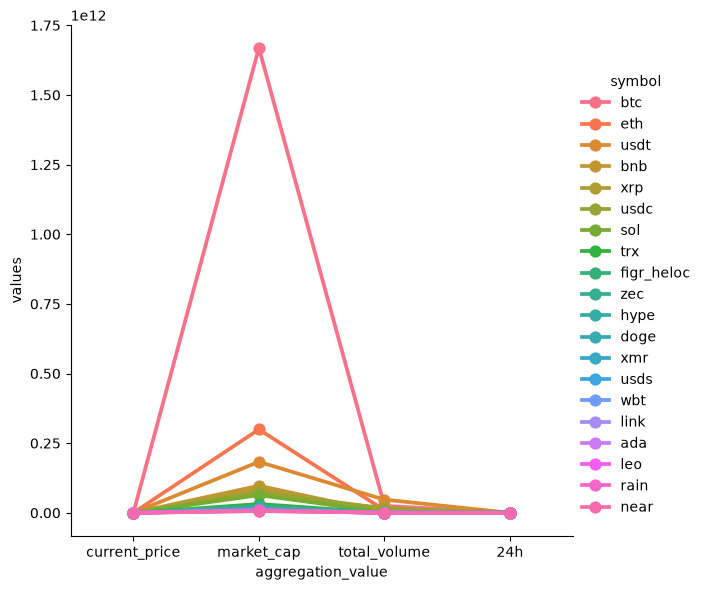

In [94]:
sns.catplot(x = 'aggregation_value', y = 'values', hue = 'symbol', data = df7, kind = 'point', height=6)

In [100]:
df7 = df.groupby('name').agg({
    'current_price': 'mean',
    'market_cap': 'max',
    'total_volume': 'mean',
    'price_change_percentage_24h': 'mean'
}).reset_index()

df7 = df7.sort_values('market_cap', ascending=False)

df7.head(10)

,name,current_price,market_cap,total_volume,price_change_percentage_24h
1,Bitcoin,83046.000000,1668756105886,25099028966.000000,1.093440
5,Ethereum,2454.450000,299438703597,9601111549.000000,2.352680
14,Tether,0.999237,183035481770,47359779974.000000,-0.008650
0,BNB,739.380000,97153680011,619635097.000000,1.741180
18,XRP,1.330000,83948029494,1345917277.000000,2.433230
15,USDC,0.999872,72083073498,16554819478.000000,-0.005510
12,Solana,107.330000,63213950711,2325863591.000000,3.265620
13,TRON,0.331314,31465860601,309091418.000000,-0.236620
6,Figure Heloc,1.021000,24513823401,17613769.000000,-0.257510
19,Zcash,1225.110000,20795949407,768407707.000000,8.223490


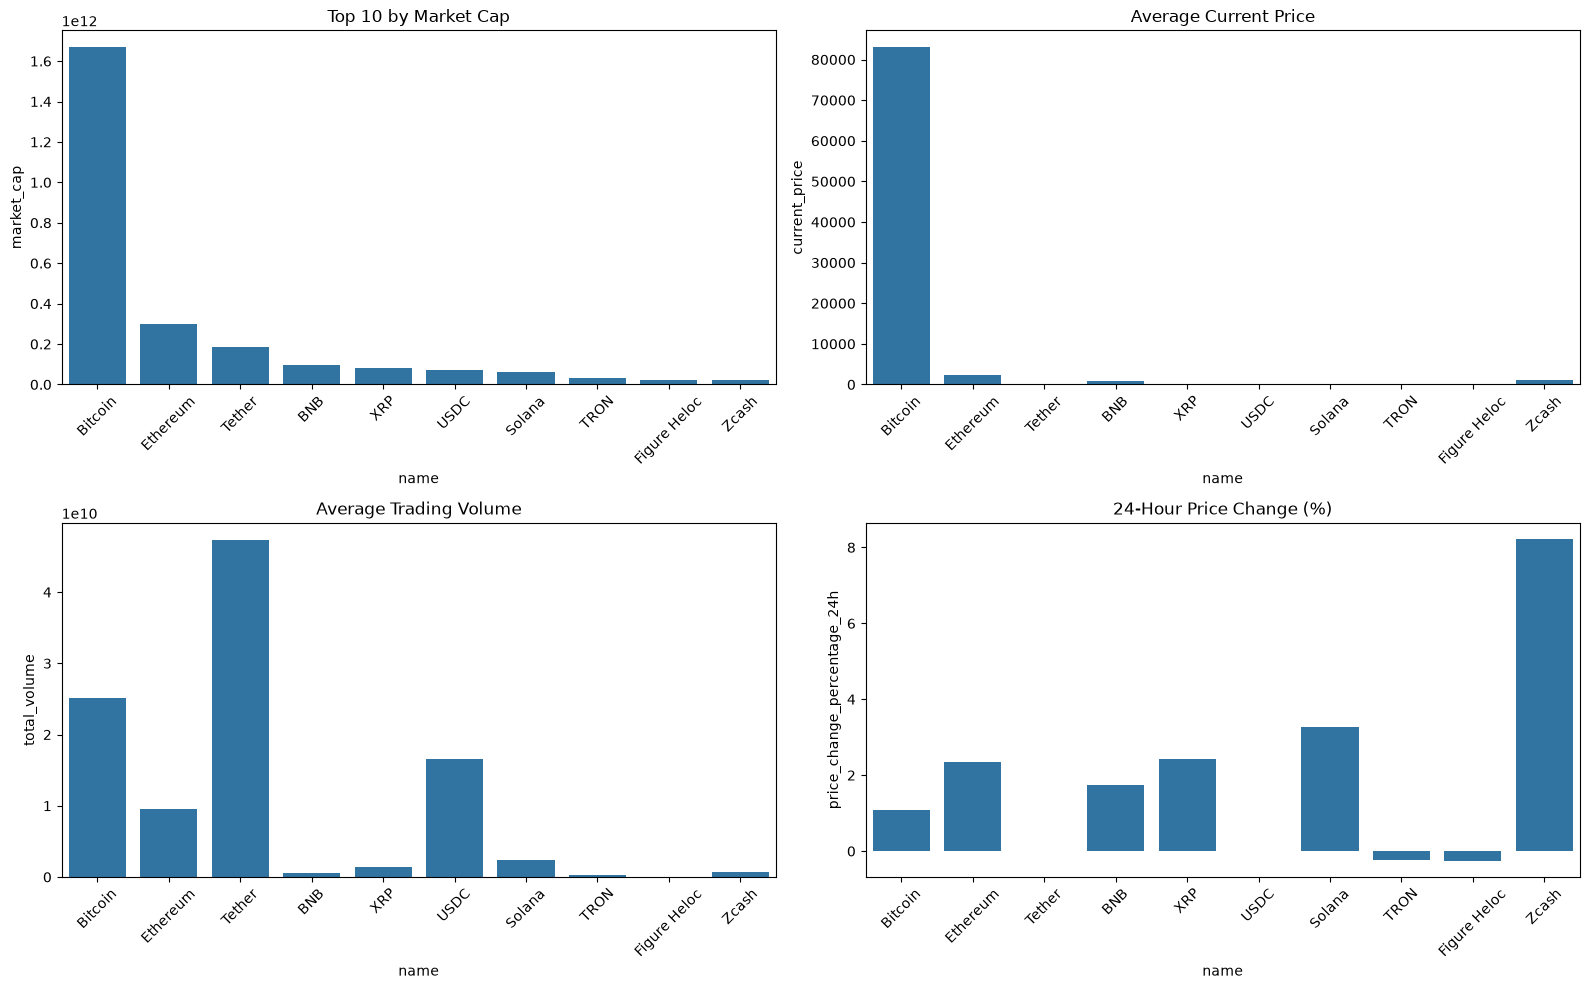

In [101]:
import matplotlib.pyplot as plt
import seaborn as sns

top10 = df7.head(10)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

sns.barplot(data=top10, x='name', y='market_cap', ax=axes[0, 0])
axes[0, 0].set_title('Top 10 by Market Cap')

sns.barplot(data=top10, x='name', y='current_price', ax=axes[0, 1])
axes[0, 1].set_title('Average Current Price')

sns.barplot(data=top10, x='name', y='total_volume', ax=axes[1, 0])
axes[1, 0].set_title('Average Trading Volume')

sns.barplot(
    data=top10, x='name',
    y='price_change_percentage_24h',
    ax=axes[1, 1]
)
axes[1, 1].set_title('24-Hour Price Change (%)')

for ax in axes.flat:
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()